# The Ship

The ship is represented as a D*D grid. Initially all cells are blocked.
A random interior cell is opened, and additional cells are iteratively opened according to the rule that they must have exactly one open neighbor. 
After the initial layout is generated, dead ends are reduced by at least half.

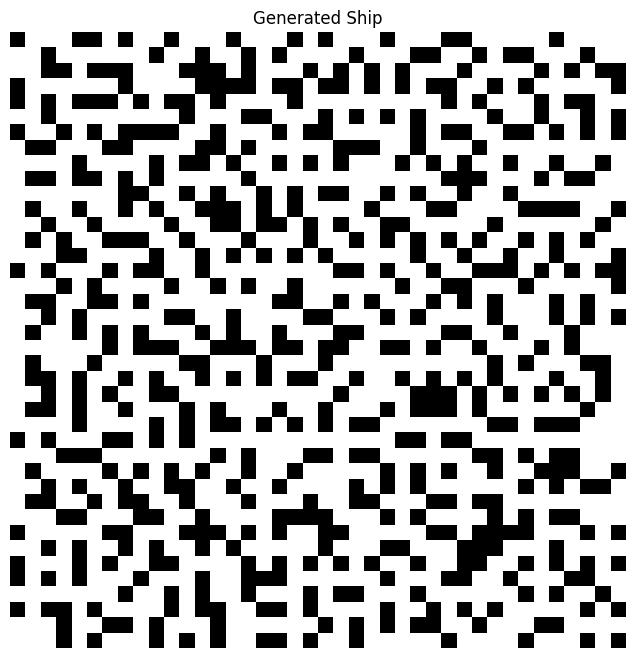

In [15]:
from Code.theShip import generate_ship
import matplotlib.pyplot as plt

#the ship
ship = generate_ship(40, seed=42)

plt.figure(figsize=(8, 8))
plt.imshow(ship, cmap="gray", interpolation="nearest")
plt.title("Generated Ship")
plt.axis("off")
plt.show()

# The Bot

The bot occupies an open cell and can move one cell per time step in the up, down, left, or right direction.

In [16]:
from Code.theBot import place_bot, get_valid_moves

bot_position = place_bot(ship, seed=10)

print("Bot position:", bot_position)
print("Valid moves:", get_valid_moves(ship, bot_position))

Bot position: (2, 20)
Valid moves: [(1, 20)]


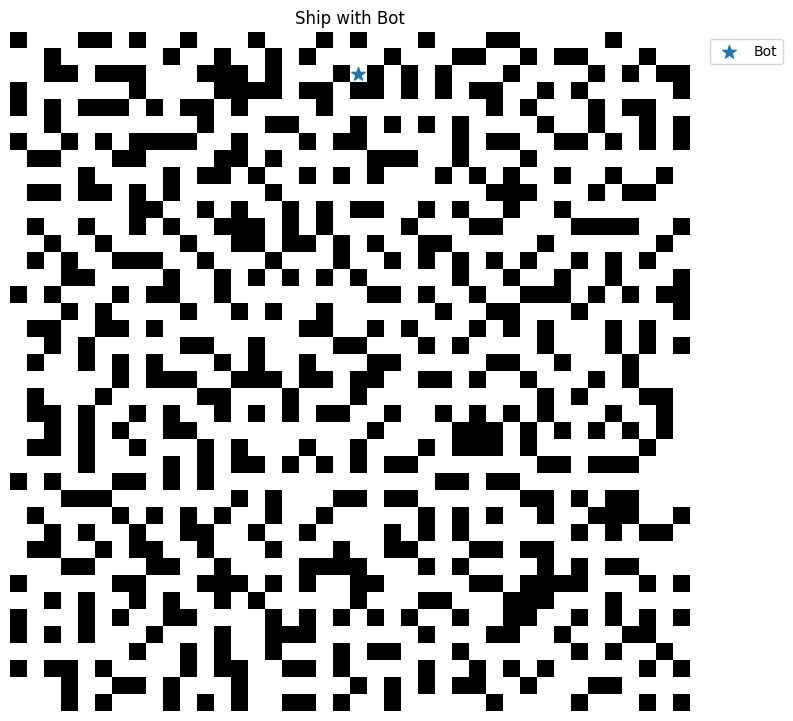

In [17]:
#visulization
plt.figure(figsize=(8, 8))
plt.imshow(ship, cmap="gray", interpolation="nearest")

row, col = bot_position
plt.scatter(col, row, s=100, marker="*", label="Bot")

plt.title("Ship with Bot")
plt.axis("off")
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

In [18]:
#fire
from Code.theFire import place_fire, spread_fire
import random

#initialize
fire_position = place_fire(ship, seed=20)

burning_cells = {fire_position}

print("Initial fire:", fire_position)

#one time step
rng = random.Random(30)

burning_cells = spread_fire(
    ship,
    burning_cells,
    q=0.5,
    rng=rng
)

print("Burning cells:", burning_cells)

Initial fire: (12, 3)
Burning cells: {(12, 4), (12, 3)}


In [19]:
#multi spread
rng = random.Random(30)

fire_position = place_fire(ship, seed=20)
burning_cells = {fire_position}

print("Time: 0", "Burning cells:", len(burning_cells))

for t in range(1, 11):
    burning_cells = spread_fire(
        ship,
        burning_cells,
        q=0.5,
        rng=rng
    )

    print("Time:", t, "Burning cells:", len(burning_cells))

Time: 0 Burning cells: 1
Time: 1 Burning cells: 2
Time: 2 Burning cells: 3
Time: 3 Burning cells: 6
Time: 4 Burning cells: 7
Time: 5 Burning cells: 10
Time: 6 Burning cells: 10
Time: 7 Burning cells: 12
Time: 8 Burning cells: 13
Time: 9 Burning cells: 18
Time: 10 Burning cells: 23


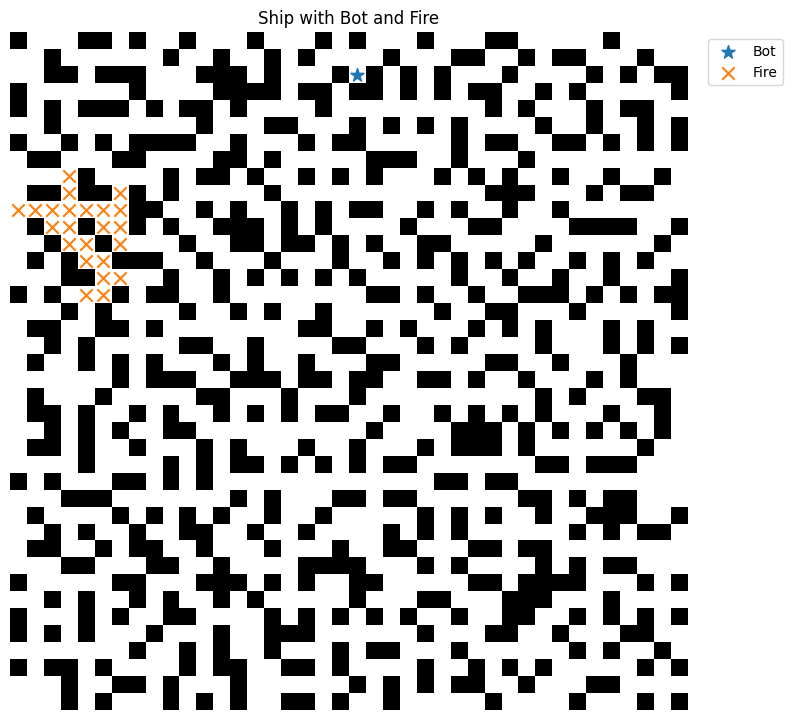

In [20]:
plt.figure(figsize=(8, 8))
plt.imshow(ship, cmap="gray", interpolation="nearest")

bot_row, bot_col = bot_position
plt.scatter(bot_col, bot_row, s=100, marker="*", label="Bot")

fire_rows = [r for r, c in burning_cells]
fire_cols = [c for r, c in burning_cells]

plt.scatter(fire_cols, fire_rows, s=80, marker="x", label="Fire")

plt.title("Ship with Bot and Fire")
plt.axis("off")
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

In [21]:
from Code.theButton import place_button

occupied = {
    bot_position,
    fire_position
}

button_position = place_button(
    ship,
    occupied=occupied,
    seed=40
)

print("Bot:", bot_position)
print("Fire:", fire_position)
print("Button:", button_position)

Bot: (2, 20)
Fire: (12, 3)
Button: (36, 20)


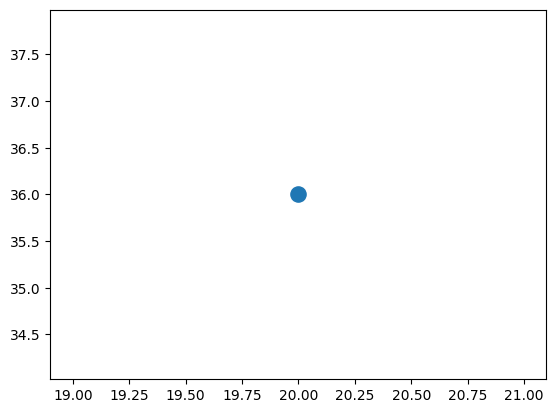

In [22]:
#the Button visualization
button_row, button_col = button_position

plt.scatter(
    button_col,
    button_row,
    s=120,
    marker="o",
    label="Button"
)